# Task–spectrum alignment with an MNUDFT task

We ask how well the query branch of a data re-uploading (DDR) circuit can be aligned with the structure of a multi-query non-uniform DFT (MNUDFT) task. The query encoding determines which query phase functions the circuit can access, and the query value determines where those phases are evaluated.

Panel (a) concerns reachability. For each number of query-encoding layers $L_f$ we compute the worst-case distance from a task query mode $\nu \in \Omega^{(f)}_\star$ to the accessible query spectrum $\Omega^{(f)}$, for dyadic generator scales $s_{\ell,n} = R_n 2^{-(\ell+1)}$ and for uniform scales $s_{\ell,n} = R_n/L_f$, and compare it with the bound $\sqrt{N} R\, 2^{-L_f}$. This panel is exact and takes seconds. Panel (b) concerns absorbability. It shows the jackknife bias-corrected spectral-prior distance $D_\Sigma$ along the ray $\boldsymbol f = t\,\boldsymbol f^\star$ for the aligned $Z_n$ query, which is not absorbable, and for a $Y_n$ control with the same generator eigenvalues, which the adjacent trainable $R_y$ block absorbs. Both are estimated from an ensemble of 1600 random parameter vectors.

**Outputs.** `figures/fig_03_approx_spectrum.pdf` (and `.png`) — the two-panel figure; `results/task_alignment/` — cached panel (b) estimates in `panel_b.npz` (corrected $D_\Sigma$, standard error and raw estimate for both arms at the 15 points of the ray).

**Runtime.** With the cached results in `results/task_alignment/` the notebook runs in under a minute. Recomputing from scratch takes about 2 minutes on a CPU (NumPy only): delete `results/task_alignment/panel_b.npz`; the seeds are fixed, so the same numbers are reproduced. Figure text is typeset with LaTeX, so a working LaTeX installation is required.

## Setup

We import NumPy and matplotlib, set the figure style and create the output directories.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "mathtext.fontset": "dejavuserif",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.4,
        "ytick.major.width": 0.4,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.fontsize": 6.5,
        "figure.titlesize": 8,
        "lines.linewidth": 1.2,
    }
)

RESULTS_DIR = Path("../results/task_alignment")
FIGURES_DIR = Path("../figures")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Task and accessible query spectrum

The reference task is the MNUDFT intensity score of a phase-only signal $a_d = e^{i x_d}$, $d = 1, \dots, D$, sampled at positions $p_d$ and evaluated at $N$ query coordinates $\boldsymbol f = (f_1, \dots, f_N)$,
$$
s(\boldsymbol x, \boldsymbol f) = \sum_{n=1}^{N} \Big| \sum_{d=1}^{D} a_d\, e^{-2\pi i p_d f_n} \Big|^2 .
$$
Expanding the modulus square, each term carries a query phase $e^{-2\pi i (p_d - p_{d'}) f_n}$, so the task query modes are
$$
\Omega^{(f)}_\star = \{ -2\pi (p_d - p_{d'})\, \boldsymbol e_n : d \neq d' \} \cup \{\boldsymbol 0\},
$$
with $\boldsymbol e_n$ the $n$-th unit vector. Every task mode has a single active query coordinate. For $\boldsymbol p = (0, 0.10, 0.45, 0.80)$ and $N = 4$ there are 41 modes, and the coordinate extent is $R = 2\pi (p_{\max} - p_{\min}) \approx 5.03$. The score itself is never fitted: we use only its mode set (panel (a)) and the function prior of the circuit along the ray $\boldsymbol f = t\,\boldsymbol f^\star$ (panel (b)). The signal-dependent coefficient functions $F_\omega(\boldsymbol x; \theta)$ are learned through $\theta$ and are not addressed here.

The next cell defines the task and its mode set. Differences such as $0.45 - 0.10$ and $0.80 - 0.45$ coincide mathematically but not necessarily in floating point, so modes are deduplicated on a rounded key.

In [2]:
SAMPLING_POSITIONS = np.array([0.0, 0.10, 0.45, 0.80])
NUMBER_OF_SAMPLES = len(SAMPLING_POSITIONS)
NUMBER_OF_QUERIES = 4
TASK_QUERY = np.array([0.30, 0.70, 1.10, 1.60])  # f^*

NUMBER_OF_QUBITS = NUMBER_OF_QUERIES
COORDINATE_EXTENT = 2.0 * np.pi * (
    SAMPLING_POSITIONS.max() - SAMPLING_POSITIONS.min()
)


def task_modes():
    """Omega^{(f)}_star as an array of shape (number of modes, N).

    Modes are deduplicated on a rounded key; the first exact value
    encountered for each key is kept.
    """
    modes = {}
    zero = (0.0,) * NUMBER_OF_QUERIES
    modes[zero] = zero
    for query in range(NUMBER_OF_QUERIES):
        for first in range(NUMBER_OF_SAMPLES):
            for second in range(NUMBER_OF_SAMPLES):
                if first == second:
                    continue
                value = -2.0 * np.pi * (
                    SAMPLING_POSITIONS[first] - SAMPLING_POSITIONS[second]
                )
                vector = [0.0] * NUMBER_OF_QUERIES
                vector[query] = value
                key = tuple(np.round(vector, 12) + 0.0)
                modes.setdefault(key, tuple(vector))
    return np.array(sorted(modes.values()))


TASK_MODES = task_modes()

Each query-encoding layer $\ell = 1, \dots, L_f$ applies $\exp(-i f_n s_{\ell,n} P_n)$ on qubit $n$, with $P_n = Z_n$ or $Y_n$ (both with eigenvalues $\pm 1$). The frequencies reachable in one coordinate are therefore $\sum_\ell c_\ell\, 2 s_{\ell,n}$ with $c_\ell \in \{-1, 0, 1\}$. The next cell builds this set for the dyadic and uniform scale schemes and computes the coverage error $\max_{\nu \in \Omega^{(f)}_\star} \mathrm{dist}(\nu, \Omega^{(f)})$ of panel (a). The scales are irrational multiples of the coordinate extent, so redundant signed-digit sums that should coincide survive as distinct floating-point values; we therefore deduplicate with a tolerance relative to the smallest scale rather than by absolute rounding.

In [3]:
def generator_scales(number_of_layers, scheme):
    """s_{l,n} for l = 1..L_f (identical for every n). Shape (L_f,)."""
    layers = np.arange(1, number_of_layers + 1)
    if scheme == "dyadic":
        return COORDINATE_EXTENT * 2.0 ** (-(layers + 1))
    if scheme == "uniform":
        return np.full(number_of_layers, COORDINATE_EXTENT / number_of_layers)
    raise ValueError("Unknown scheme.")


def accessible_coordinate_spectrum(scales):
    """All frequencies reachable in one query coordinate."""
    values = np.array([0.0])
    for scale in scales:
        values = np.concatenate(
            [values - 2.0 * scale, values, values + 2.0 * scale]
        )
    resolution = 2.0 * np.min(np.abs(scales))
    keys = np.round(values / resolution, 6)
    _, first = np.unique(keys, return_index=True)
    return np.sort(values[first])


def coverage_error(number_of_layers, scheme):
    """max_{nu in Omega*} dist(nu, Omega^{(f)}), the quantity of panel (a)."""
    spectrum = accessible_coordinate_spectrum(
        generator_scales(number_of_layers, scheme)
    )
    distances = []
    for mode in TASK_MODES:
        squared = 0.0
        for value in mode:
            squared += np.min((spectrum - value) ** 2)
        distances.append(np.sqrt(squared))
    return float(np.max(distances))

## Circuit

We simulate the DDR circuit as a statevector on $N = 4$ qubits, starting from $|0000\rangle$, with $L = 2$ re-uploading layers and observable $\langle Z_0 \rangle$. Each layer applies, in order, the signal encoding $\bigotimes_n R_y(x_n)$ (one feature per qubit), a trainable block $\mathrm{CNOT}_{\mathrm{ring}} \cdot \bigotimes_n R_y(\theta_{0,\ell,n})$, the query encoding $\bigotimes_n \exp(-i f_n s_{\ell,n} P_n)$, and a second trainable block with angles $\theta_{1,\ell,n}$. The query generator is $P_n = Z_n$ (aligned) or $P_n = Y_n$ (control), with dyadic scales. Since $Y_n$ commutes with the adjacent $R_y$ rotations, the $Y_n$ query is absorbed by the shift $\theta_{1,\ell,n} \to \theta_{1,\ell,n} + 2 s_{\ell,n} f_n$; $Z_n$ does not commute with $R_y$ and is not absorbable.

The first cell sets up the dimensions, the Pauli matrices, the observable and the CNOT ring.

In [4]:
DIMENSION = 2**NUMBER_OF_QUBITS
NUMBER_OF_LAYERS = 2
X_MODES = np.arange(-NUMBER_OF_LAYERS, NUMBER_OF_LAYERS + 1)
X_GRID_SIZE = len(X_MODES)

PAULI_Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
PAULI_Z = np.diag([1.0, -1.0]).astype(complex)


def pauli_diagonal(qubit, matrix):
    bits = (np.arange(DIMENSION) >> (NUMBER_OF_QUBITS - 1 - qubit)) & 1
    return np.where(bits == 0, matrix[0, 0].real, matrix[1, 1].real)


OBSERVABLE = pauli_diagonal(0, PAULI_Z)


def cnot(control, target):
    matrix = np.zeros((DIMENSION, DIMENSION), dtype=complex)
    for state in range(DIMENSION):
        bit = (state >> (NUMBER_OF_QUBITS - 1 - control)) & 1
        image = state ^ (1 << (NUMBER_OF_QUBITS - 1 - target)) if bit else state
        matrix[image, state] = 1.0
    return matrix


CNOT_RING = np.eye(DIMENSION, dtype=complex)
for _q in range(NUMBER_OF_QUBITS):
    CNOT_RING = cnot(_q, (_q + 1) % NUMBER_OF_QUBITS) @ CNOT_RING

The gates are batched over parameter samples. `rotation_layer` builds $\bigotimes_n \exp(-i \phi_n G/2)$ for a batch of angle vectors, and `evaluate` returns $\langle Z_0 \rangle$ for a batch of parameter vectors at a set of signal points.

In [5]:
def rotation_layer(angles, generator):
    """Batched tensor_n exp(-i angles[:, n] generator / 2)."""
    batch = angles.shape[0]
    result = np.ones((batch, 1, 1), dtype=complex)
    for index in range(angles.shape[1]):
        half = 0.5 * angles[:, index]
        block = (
            np.cos(half)[:, None, None] * np.eye(2)[None]
            - 1j * np.sin(half)[:, None, None] * generator[None]
        )
        result = np.einsum("bij,bkl->bikjl", result, block).reshape(
            batch, result.shape[1] * 2, result.shape[2] * 2
        )
    return result


def trainable_block(angles):
    return CNOT_RING @ rotation_layer(angles, PAULI_Y)


def query_unitary(query, scales, layer, generator_name):
    """exp(-i sum_n f_n s_{l,n} P_n) for P = Z (aligned) or Y (control)."""
    angles = 2.0 * scales[layer] * query[None, :]
    generator = PAULI_Z if generator_name == "Z" else PAULI_Y
    return rotation_layer(angles, generator)[0]


def evaluate(parameters, signal_points, query, scales, generator_name):
    """<Z_0> from |0000>. parameters (B, 2, L, n_q). Returns (B, P)."""
    batch = parameters.shape[0]
    state = np.broadcast_to(
        np.eye(DIMENSION, dtype=complex)[0],
        (batch, signal_points.shape[0], DIMENSION),
    ).copy()
    query_gates = [
        query_unitary(query, scales, layer, generator_name)
        for layer in range(NUMBER_OF_LAYERS)
    ]
    for layer in range(NUMBER_OF_LAYERS):
        encoding = rotation_layer(signal_points, PAULI_Y)
        state = np.einsum("pij,bpj->bpi", encoding, state)
        state = np.einsum(
            "bij,bpj->bpi", trainable_block(parameters[:, 0, layer]), state
        )
        state = np.einsum("ij,bpj->bpi", query_gates[layer], state)
        state = np.einsum(
            "bij,bpj->bpi", trainable_block(parameters[:, 1, layer]), state
        )
    return np.einsum("bpj,j->bp", np.abs(state) ** 2, OBSERVABLE)

## Spectral-prior distance

For a fixed query $\boldsymbol f$ the circuit is a trigonometric polynomial in $\boldsymbol x$ with frequencies in $\{-L, \dots, L\}^N$. Its Fourier coefficient vector $c(\theta; \boldsymbol f)$ is obtained exactly by an FFT over a $(2L+1)^N$ grid, and the second-moment matrix $\Sigma(\boldsymbol f) = \mathbb{E}_\theta[c\, c^\dagger]$ characterises the function prior. The spectral-prior distance is
$$
D_\Sigma = 1 - \frac{\mathrm{Re}\,\mathrm{Tr}[\Sigma(\boldsymbol f)^\dagger \Sigma(\boldsymbol 0)]}{\|\Sigma(\boldsymbol f)\|_F\, \|\Sigma(\boldsymbol 0)\|_F} .
$$
The next cell computes the coefficient vectors, the distance between two second-moment matrices, and the block-wise Gram matrices needed for the jackknife.

In [6]:
SIGNAL_GRID_1D = 2.0 * np.pi * np.arange(X_GRID_SIZE) / X_GRID_SIZE
SIGNAL_GRID = np.stack(
    np.meshgrid(*([SIGNAL_GRID_1D] * NUMBER_OF_QUBITS), indexing="ij"), axis=-1
).reshape(-1, NUMBER_OF_QUBITS)


def coefficient_vectors(parameters, query, scales, generator_name):
    """Fourier coefficients over x for each parameter sample."""
    values = evaluate(parameters, SIGNAL_GRID, query, scales, generator_name)
    axes = tuple(range(1, NUMBER_OF_QUBITS + 1))
    spectrum = np.fft.fftn(
        values.reshape(parameters.shape[0], *([X_GRID_SIZE] * NUMBER_OF_QUBITS)),
        axes=axes,
    ) / X_GRID_SIZE**NUMBER_OF_QUBITS
    return spectrum.reshape(parameters.shape[0], -1)


def _alignment_distance(first, second):
    """1 - normalized Frobenius alignment of two second-moment matrices."""
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator < 1e-30:
        return 0.0
    return 1.0 - np.clip(
        np.real(np.vdot(first, second)) / denominator, 0.0, 1.0
    )


def _gram_blocks(vectors, number_of_blocks):
    """Total Gram matrix and per-block Gram matrices."""
    blocks = np.array_split(np.arange(vectors.shape[0]), number_of_blocks)
    partial = [
        vectors[index].conj().T @ vectors[index] for index in blocks
    ]
    total = sum(partial)
    sizes = np.array([len(index) for index in blocks])
    return total, partial, sizes

The raw estimator of $D_\Sigma$ is biased upward at a finite ensemble size $N_\theta$: $\Sigma(\boldsymbol f)$ and $\Sigma(\boldsymbol 0)$ are both norm-inflated by independent sampling noise, and since the norms enter the denominator, the normalized alignment falls below one even when the two populations are identical. The bias is $O(1/N_\theta)$, which a delete-a-block jackknife removes. Both matrices are built from the same parameter ensemble, so each leave-one-out replicate deletes the same block from both; deleting independently would estimate the bias of an uncorrelated pair and undercorrect. Parameters are drawn uniformly from $[0, 2\pi)$, which is equivalent to $[0, 4\pi)$ for expectation values (checked below).

In [7]:
def jackknife_prior_distance(scale_parameter, scales, generator_name,
                             rng, number_of_samples, number_of_blocks=10,
                             batch_size=100):
    """Jackknife bias-corrected D_Sigma along the ray f = t f^*.

    Returns the corrected estimate, its jackknife standard error, and the raw
    estimate, each of shape (len(scale_parameter),).
    """
    parameters = rng.uniform(
        0.0, 2.0 * np.pi,
        (number_of_samples, 2, NUMBER_OF_LAYERS, NUMBER_OF_QUBITS),
    )

    def gram_at(query):
        vectors = []
        for start in range(0, number_of_samples, batch_size):
            vectors.append(coefficient_vectors(
                parameters[start:start + batch_size], query,
                scales, generator_name,
            ))
        return _gram_blocks(
            np.concatenate(vectors, axis=0), number_of_blocks
        )

    reference_total, reference_partial, sizes = gram_at(
        np.zeros(NUMBER_OF_QUBITS)
    )

    corrected, errors, raw = [], [], []
    for value in scale_parameter:
        total, partial, _ = gram_at(value * TASK_QUERY)
        full = _alignment_distance(
            total / number_of_samples, reference_total / number_of_samples
        )
        replicates = []
        for index in range(number_of_blocks):
            retained = number_of_samples - sizes[index]
            replicates.append(_alignment_distance(
                (total - partial[index]) / retained,
                (reference_total - reference_partial[index]) / retained,
            ))
        replicates = np.array(replicates)
        mean = replicates.mean()
        corrected.append(
            number_of_blocks * full - (number_of_blocks - 1) * mean
        )
        errors.append(np.sqrt(
            (number_of_blocks - 1) / number_of_blocks
            * np.sum((replicates - mean) ** 2)
        ))
        raw.append(full)
    return np.array(corrected), np.array(errors), np.array(raw)

## Consistency checks

We check every claim that enters the figure independently of the plotting code: the task mode set, the accessible query spectrum, the reachability bound, exact absorbability of the $Y_n$ control, non-absorbability of the $Z_n$ query, and the periodicity of the parameter ensemble. Each check prints its result and raises an `AssertionError` if it fails. The first cell defines the reporting helper and prints the problem size.

In [8]:
def report(name, passed, detail=""):
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}"
          f"{('  ' + detail) if detail else ''}")
    assert passed, name


print("Setup")
print(f"  qubits {NUMBER_OF_QUBITS}, dimension {DIMENSION}")
print(f"  signal samples D = {NUMBER_OF_SAMPLES}, "
      f"query coordinates N = {NUMBER_OF_QUERIES}")
print(f"  task modes |Omega*| = {len(TASK_MODES)}")
print(f"  coordinate extent R = {COORDINATE_EXTENT:.4f}")

Setup
  qubits 4, dimension 16
  signal samples D = 4, query coordinates N = 4
  task modes |Omega*| = 41
  coordinate extent R = 5.0265


### Task modes

The mode set should contain 41 modes, including the zero mode, each with at most one active coordinate and all within the coordinate extent.

In [9]:
print("\nTask modes")

report("41 distinct task modes (10 nonzero per coordinate, plus zero)",
       len(TASK_MODES) == 41, f"got {len(TASK_MODES)}")
report(
    "every task mode has at most one active query coordinate",
    all(np.count_nonzero(mode) <= 1 for mode in TASK_MODES),
)
report(
    "task modes lie within the coordinate extent",
    np.abs(TASK_MODES).max() <= COORDINATE_EXTENT + 1e-12,
    f"max |nu| = {np.abs(TASK_MODES).max():.4f}",
)
report("the zero mode is present", any(
    np.allclose(mode, 0.0) for mode in TASK_MODES
))


Task modes
  [PASS] 41 distinct task modes (10 nonzero per coordinate, plus zero)  got 41
  [PASS] every task mode has at most one active query coordinate
  [PASS] task modes lie within the coordinate extent  max |nu| = 5.0265
  [PASS] the zero mode is present


### Accessible query spectrum

The signed-digit representation is redundant, so $3^{L_f}$ is only an upper bound on the number of distinct frequencies per coordinate, attained only when digits do not collide. With dyadic scales they do collide, e.g. $0 \cdot \tfrac12 + 1 \cdot \tfrac14 = 1 \cdot \tfrac12 - 1 \cdot \tfrac14$. Instead, dyadic scales should give a uniform lattice of $2^{L_f+1} - 1$ frequencies with spacing $R\, 2^{-L_f}$, symmetric under $\omega \to -\omega$ and spanning $\pm R (1 - 2^{-L_f})$.

In [10]:
print("\nAccessible query spectrum")

for layers in (1, 2, 3, 4):
    spectrum = accessible_coordinate_spectrum(
        generator_scales(layers, "dyadic")
    )
    report(
        f"L_f = {layers}: at most 3^L_f = {3**layers} distinct frequencies",
        len(spectrum) <= 3**layers,
        f"got {len(spectrum)}",
    )

for layers in (2, 4, 6, 8):
    spectrum = accessible_coordinate_spectrum(
        generator_scales(layers, "dyadic")
    )
    gap = np.diff(spectrum).max()
    predicted = COORDINATE_EXTENT * 2.0 ** (-layers)
    report(
        f"L_f = {layers}: spacing equals R 2^(-L_f)",
        abs(gap - predicted) < 1e-9,
        f"gap {gap:.3e}, predicted {predicted:.3e}",
    )

spectrum = accessible_coordinate_spectrum(generator_scales(6, "dyadic"))
report(
    "spectrum spans +- R (1 - 2^-L_f)",
    abs(spectrum.max() - COORDINATE_EXTENT * (1.0 - 2.0 ** (-6))) < 1e-9,
    f"max {spectrum.max():.4f}",
)
report(
    "dyadic scales give a uniform lattice of 2^(L_f+1)-1 frequencies",
    len(spectrum) == 2**7 - 1,
    f"got {len(spectrum)}",
)

spectrum = accessible_coordinate_spectrum(generator_scales(4, "dyadic"))
report(
    "spectrum is symmetric under omega -> -omega",
    np.allclose(spectrum, -spectrum[::-1]),
)


Accessible query spectrum
  [PASS] L_f = 1: at most 3^L_f = 3 distinct frequencies  got 3
  [PASS] L_f = 2: at most 3^L_f = 9 distinct frequencies  got 7
  [PASS] L_f = 3: at most 3^L_f = 27 distinct frequencies  got 15
  [PASS] L_f = 4: at most 3^L_f = 81 distinct frequencies  got 31
  [PASS] L_f = 2: spacing equals R 2^(-L_f)  gap 1.257e+00, predicted 1.257e+00
  [PASS] L_f = 4: spacing equals R 2^(-L_f)  gap 3.142e-01, predicted 3.142e-01
  [PASS] L_f = 6: spacing equals R 2^(-L_f)  gap 7.854e-02, predicted 7.854e-02
  [PASS] L_f = 8: spacing equals R 2^(-L_f)  gap 1.963e-02, predicted 1.963e-02
  [PASS] spectrum spans +- R (1 - 2^-L_f)  max 4.9480
  [PASS] dyadic scales give a uniform lattice of 2^(L_f+1)-1 frequencies  got 127
  [PASS] spectrum is symmetric under omega -> -omega


### Reachability bound

The dyadic coverage error should respect the bound $\sqrt{N} R\, 2^{-L_f}$ and halve with each added layer. Uniform scales resolve the extent with spacing $2R/L_f$, so their coverage error falls only polynomially; the contrast is exponential versus polynomial convergence, not convergence versus none.

In [11]:
print("\nTheorem 1")

layer_range = np.arange(1, 11)
errors = np.array([coverage_error(layers, "dyadic") for layers in layer_range])
bounds = np.sqrt(NUMBER_OF_QUERIES) * COORDINATE_EXTENT * 2.0 ** (-layer_range)

report("dyadic coverage error respects the bound", np.all(errors <= bounds),
       f"max ratio {np.max(errors / bounds):.4f}")
ratios = errors[:-1] / errors[1:]
report("dyadic coverage error halves each layer",
       np.allclose(ratios, 2.0, atol=1e-9),
       f"ratios in [{ratios.min():.4f}, {ratios.max():.4f}]")

uniform_errors = np.array([
    coverage_error(layers, "uniform") for layers in layer_range
])
report("mismatched scales converge only polynomially",
       uniform_errors[-1] / errors[-1] > 10.0,
       f"L_f=10: uniform {uniform_errors[-1]:.3e} vs "
       f"dyadic {errors[-1]:.3e}, ratio {uniform_errors[-1]/errors[-1]:.1f}")
report("the advantage of the dyadic scales grows with depth",
       (uniform_errors / errors)[-1] > 4.0 * (uniform_errors / errors)[3],
       f"ratio L_f=4 {(uniform_errors/errors)[3]:.1f} -> "
       f"L_f=10 {(uniform_errors/errors)[-1]:.1f}")


Theorem 1
  [PASS] dyadic coverage error respects the bound  max ratio 0.5000
  [PASS] dyadic coverage error halves each layer  ratios in [2.0000, 2.0000]
  [PASS] mismatched scales converge only polynomially  L_f=10: uniform 3.770e-01 vs dyadic 4.909e-03, ratio 76.8
  [PASS] the advantage of the dyadic scales grows with depth  ratio L_f=4 2.0 -> L_f=10 76.8


### Absorbability

We draw a few parameter vectors and signal points, shift the second trainable angles by $2 s_{\ell,n} f_n$ and evaluate the circuit at zero query. For the $Y_n$ query this reproduces the original outputs to machine precision; for the $Z_n$ query it does not. Both generators have eigenvalues $\pm 1$, so the two arms share $\Omega^{(f)}$.

In [12]:
print("\nAbsorbability (Proposition 7)")

scales = generator_scales(NUMBER_OF_LAYERS, "dyadic")
rng = np.random.default_rng(0)
parameters = rng.uniform(
    0.0, 4.0 * np.pi,
    (4, 2, NUMBER_OF_LAYERS, NUMBER_OF_QUBITS),
)
signal = rng.uniform(0.0, 2.0 * np.pi, (40, NUMBER_OF_QUBITS))
query = TASK_QUERY

shifted = parameters.copy()
for layer in range(NUMBER_OF_LAYERS):
    shifted[:, 1, layer, :] = (
        parameters[:, 1, layer, :] + 2.0 * scales[layer] * query
    )

control_query = evaluate(parameters, signal, query, scales, "Y")
control_zero = evaluate(shifted, signal, np.zeros_like(query), scales, "Y")
residual = np.abs(control_query - control_zero).max()
report(
    "Y_n query is exactly absorbed by shifting the adjacent R_y block",
    residual < 1e-12, f"max residual {residual:.2e}",
)

aligned_query = evaluate(parameters, signal, query, scales, "Z")
aligned_zero = evaluate(shifted, signal, np.zeros_like(query), scales, "Z")
residual = np.abs(aligned_query - aligned_zero).max()
report(
    "Z_n query is not absorbed by the same shift",
    residual > 0.1, f"max residual {residual:.3f}",
)

report(
    "Y_n and Z_n generators share their eigenvalues, hence Omega^(f)",
    np.allclose(
        np.sort(np.linalg.eigvalsh(PAULI_Y)),
        np.sort(np.linalg.eigvalsh(PAULI_Z)),
    ),
)


Absorbability (Proposition 7)
  [PASS] Y_n query is exactly absorbed by shifting the adjacent R_y block  max residual 1.36e-15
  [PASS] Z_n query is not absorbed by the same shift  max residual 1.248
  [PASS] Y_n and Z_n generators share their eigenvalues, hence Omega^(f)


### Parameter periodicity

$R_y(\theta)$ has period $4\pi$ as a unitary, but $R_y(\theta + 2\pi) = -R_y(\theta)$, and the global sign cancels in any expectation value. Sampling $\theta$ over $[0, 2\pi)$, as in panel (b), or over $[0, 4\pi)$ therefore induces the same distribution over circuit functions.

In [13]:
print("\nParameter ensemble periodicity")

def rotation(angle):
    return np.cos(0.5 * angle) * np.eye(2) - 1j * np.sin(0.5 * angle) * PAULI_Y


report(
    "R_y(theta + 2 pi) = - R_y(theta)",
    np.abs(rotation(1.234 + 2.0 * np.pi) + rotation(1.234)).max() < 1e-14,
)

shifted_by_period = parameters.copy()
shifted_by_period[:, 1, 0, 0] += 2.0 * np.pi
report(
    "expectation values are invariant under theta -> theta + 2 pi",
    np.abs(
        evaluate(parameters, signal, query, scales, "Y")
        - evaluate(shifted_by_period, signal, query, scales, "Y")
    ).max() < 1e-12,
)

print("\nAll checks passed.")


Parameter ensemble periodicity
  [PASS] R_y(theta + 2 pi) = - R_y(theta)
  [PASS] expectation values are invariant under theta -> theta + 2 pi

All checks passed.


## Run or load results

Panel (a) uses $L_f = 1, \dots, 10$. Panel (b) uses $N_\theta = 1600$ parameter samples, 10 jackknife blocks and 15 points $t \in [0, 2]$ on the ray.

In [14]:
LAYER_RANGE = np.arange(1, 11)
RAY = np.linspace(0.0, 2.0, 15)
ENSEMBLE = 1600
BLOCKS = 10

Panel (a) is exact and cheap, so we always compute it: the coverage error for both scale schemes and the bound $\sqrt{N} R\, 2^{-L_f}$.

In [15]:
dyadic_error = np.array([coverage_error(t, "dyadic") for t in LAYER_RANGE])
uniform_error = np.array([coverage_error(t, "uniform") for t in LAYER_RANGE])
bound = (
    np.sqrt(NUMBER_OF_QUERIES) * COORDINATE_EXTENT
    * 2.0 ** (-LAYER_RANGE.astype(float))
)

Panel (b) is loaded from `results/task_alignment/panel_b.npz` when present. Otherwise both arms are computed with seed 11, so that they see the same parameter ensemble, and the result is cached.

In [16]:
CACHE = RESULTS_DIR / "panel_b.npz"
if CACHE.exists():
    cached = np.load(CACHE)
    aligned, aligned_error, aligned_raw = (
        cached["aligned"], cached["aligned_error"], cached["aligned_raw"]
    )
    control, control_error, control_raw = (
        cached["control"], cached["control_error"], cached["control_raw"]
    )
    print(f"panel (b) loaded from {CACHE}")
else:
    scales = generator_scales(NUMBER_OF_LAYERS, "dyadic")
    aligned, aligned_error, aligned_raw = jackknife_prior_distance(
        RAY, scales, "Z", np.random.default_rng(11), ENSEMBLE, BLOCKS
    )
    control, control_error, control_raw = jackknife_prior_distance(
        RAY, scales, "Y", np.random.default_rng(11), ENSEMBLE, BLOCKS
    )
    np.savez(
        CACHE, aligned=aligned, aligned_error=aligned_error,
        aligned_raw=aligned_raw, control=control,
        control_error=control_error, control_raw=control_raw,
    )
    print(f"panel (b) computed and saved to {CACHE}")

panel (b) loaded from ../results/task_alignment/panel_b.npz


We print the key numbers of both panels. By absorbability, the exact $D_\Sigma$ of the $Y_n$ control vanishes for all $t$. The raw estimator shows a finite-sample floor (up to $\approx 0.08$); the jackknife correction reduces it to $\approx 0.01$, small compared with the $Z_n$ arm ($\approx 0.2$–$0.35$). The remaining residual is a few jackknife standard errors, so the correction removes most but not all of the finite-sample bias.

In [17]:
print("\nsummary")
print(f"  (a) L_f=6: dyadic {dyadic_error[5]:.3e}  uniform {uniform_error[5]:.3e}"
      f"  bound {bound[5]:.3e}")
print(f"      ratio uniform/dyadic: L_f=4 {uniform_error[3]/dyadic_error[3]:.1f}"
      f"  L_f=10 {uniform_error[-1]/dyadic_error[-1]:.1f}")
print(f"  (b) N_theta={ENSEMBLE}, {BLOCKS} jackknife blocks")
print(f"      aligned  raw {aligned_raw.max():.4f} -> corrected "
      f"{aligned.max():.4f} +- {aligned_error[np.argmax(aligned)]:.4f}")
print(f"      control  raw {control_raw.max():.4f} -> corrected "
      f"{control.max():.4f} +- {control_error[np.argmax(control)]:.4f}")
significance = np.abs(control) / np.maximum(control_error, 1e-12)
print(f"      control |D|/SE: max {significance.max():.2f}, "
      f"median {np.median(significance):.2f}")


summary
  (a) L_f=6: dyadic 7.854e-02  uniform 6.283e-01  bound 1.571e-01
      ratio uniform/dyadic: L_f=4 2.0  L_f=10 76.8
  (b) N_theta=1600, 10 jackknife blocks
      aligned  raw 0.3886 -> corrected 0.3454 +- 0.0102
      control  raw 0.0810 -> corrected 0.0119 +- 0.0037
      control |D|/SE: max 3.70, median 2.63


## Figure

Colours, legend labels and the legend frame shared by both panels.

In [18]:
COLORS = {
    "aligned": "#E64B35",
    "control": "#4DBBD5",
    "bound": "#7E6148",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}
LABELS = {
    "dyadic": r"dyadic, $s_{\ell,n}=R_n2^{-(\ell+1)}$",
    "uniform": r"uniform, $s_{\ell,n}=R_n/L_f$",
    "bound": r"bound, $\sqrt{N}R\,2^{-L_f}$",
    "aligned": r"$Z_n$ query (nonabsorbable)",
    "control": r"$Y_n$ query (absorbable)",
}
LEGEND_STYLE = dict(frameon=True, framealpha=0.9, edgecolor="black",
                    fancybox=False)

Panel (a) shows the coverage error against $L_f$ on a logarithmic scale. Panel (b) shows $D_\Sigma$ along the ray with 95% bands ($\pm 1.96$ jackknife standard errors), with the task query $t = 1$ marked. The figure is saved as PDF and PNG.

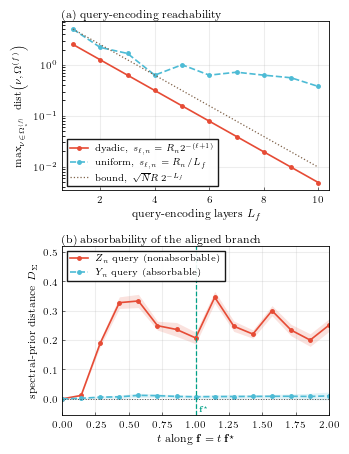

In [19]:
fig = plt.figure(figsize=(3.375, 4.45), layout="constrained")
fig.get_layout_engine().set(h_pad=0.05, hspace=0.06)
axes = fig.subplots(2, 1)

# (a) reachability of the task modes under the query encoding
axis = axes[0]
axis.semilogy(LAYER_RANGE, dyadic_error, color=COLORS["aligned"],
              marker="o", ms=2.5, label=LABELS["dyadic"])
axis.semilogy(LAYER_RANGE, uniform_error, color=COLORS["control"],
              marker="o", ms=2.5, ls="--", label=LABELS["uniform"])
axis.semilogy(LAYER_RANGE, bound, color=COLORS["bound"], lw=0.9, ls=":",
              label=LABELS["bound"])
axis.set_xlim(0.6, 10.4)
axis.set_xticks([2, 4, 6, 8, 10])
axis.set_xlabel(r"query-encoding layers $L_f$")
axis.set_ylabel(
    r"$\max_{\nu\in\Omega^{(f)}_\star}\ \mathrm{dist}\!\left(\nu,\Omega^{(f)}\right)$",
    fontsize=7.4,
)
axis.set_title("(a) query-encoding reachability", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(loc="lower left", **LEGEND_STYLE)

# (b) bias-corrected spectral-prior distance along the ray f = t f^*
axis = axes[1]
for arm, values, errors in (
    ("aligned", aligned, aligned_error),
    ("control", control, control_error),
):
    axis.fill_between(RAY, values - 1.96 * errors, values + 1.96 * errors,
                      color=COLORS[arm], alpha=0.16, linewidth=0)
    axis.plot(RAY, values, color=COLORS[arm], marker="o", ms=2.5,
              ls="-" if arm == "aligned" else "--", label=LABELS[arm])
axis.axhline(0.0, color=COLORS["reference"], ls=":", lw=0.7)
axis.axvline(1.0, color=COLORS["geometry"], ls="--", lw=0.9)
upper = float((aligned + 1.96 * aligned_error).max())
axis.set_xlim(0.0, 2.0)
axis.set_ylim(-0.055, upper * 1.42)
axis.annotate(
    r"$\mathbf{f}^\star$",
    xy=(1.0, axis.get_ylim()[0]),
    xytext=(2.5, 2.0),
    textcoords="offset points",
    color=COLORS["geometry"],
    fontsize=6.0,
    va="bottom",
)
axis.set_xlabel(r"$t$ along $\mathbf{f}=t\,\mathbf{f}^\star$")
axis.set_ylabel(r"spectral-prior distance $D_\Sigma$", fontsize=7.4)
axis.set_title("(b) absorbability of the aligned branch", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(loc="upper left", **LEGEND_STYLE)

figure_stem = FIGURES_DIR / "fig_03_approx_spectrum"
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()

## Summary

With dyadic generator scales the worst-case distance from the task modes to the accessible query spectrum halves with each query-encoding layer and stays within $\sqrt{N} R\, 2^{-L_f}$, while uniform scales converge only polynomially (a factor of about 77 larger at $L_f = 10$). Along the ray $\boldsymbol f = t\,\boldsymbol f^\star$ the aligned $Z_n$ query moves the function prior, with a corrected $D_\Sigma$ of up to about $0.35$, whereas the isospectral $Y_n$ control, which the adjacent trainable block absorbs, stays at the level of the residual finite-sample bias ($\approx 0.01$).